# 02 - Exploratory Data Analysis: Telco Customer Churn

**Goal:** Understand churn drivers using the processed Telco dataset, and produce evidence-based findings to hand off to the Power BI team (Member 7).

**Inputs:**
- `telco_processed.csv` — cleaned customer-level features
- `customer_ids.csv` — customerID lookup (same row order/index)

**Outputs:**
- Figures saved to `reports/figures/`
- Key findings summarized at the end of this notebook


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 110
FIG_DIR = '../reports/figures'


## 1. Load and merge data

In [2]:
ids = pd.read_csv('/mnt/user-data/uploads/customer_ids.csv', index_col=0)
df = pd.read_csv('/mnt/user-data/uploads/telco_processed.csv')

# Both files share the same row order/index, so we attach customerID back
df.insert(0, 'customerID', ids['customerID'].values)

print(df.shape)
df.head()


(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   str    
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# No missing values, all rows aligned 1:1 with the id file
print("Missing values:", df.isna().sum().sum())
print("Duplicate customerIDs:", df['customerID'].duplicated().sum())


Missing values: 0
Duplicate customerIDs: 0


## 2. Derived fields

We add a numeric churn flag and two grouping variables (tenure buckets, monthly-charge quartiles) to make group-by analysis and charting cleaner.

In [5]:
df['ChurnFlag'] = (df['Churn'] == 'Yes').astype(int)

bins = [0,12,24,36,48,60,72]
labels = ['0-12','13-24','25-36','37-48','49-60','61-72']
df['tenure_group'] = pd.cut(df['tenure'], bins=bins, labels=labels, include_lowest=True)

df['charges_group'] = pd.qcut(df['MonthlyCharges'], 4, labels=['Low','Mid-Low','Mid-High','High'])

df.to_csv('telco_with_ids.csv', index=False)
df[['customerID','tenure','tenure_group','MonthlyCharges','charges_group','Churn']].head()


,customerID,tenure,tenure_group,MonthlyCharges,charges_group,Churn
0,7590-VHVEG,1,0-12,29.85,Low,No
1,5575-GNVDE,34,25-36,56.95,Mid-Low,No
2,3668-QPYBK,2,0-12,53.85,Mid-Low,Yes
3,7795-CFOCW,45,37-48,42.30,Mid-Low,No
4,9237-HQITU,2,0-12,70.70,Mid-High,Yes


## 3. Overall churn rate

In [6]:
total_customers = len(df)
churned_customers = df['ChurnFlag'].sum()
churn_rate = churned_customers / total_customers * 100

print(f"Total customers:   {total_customers}")
print(f"Churned customers: {churned_customers}")
print(f"Overall churn rate: {churn_rate:.2f}%")


Total customers:   7043
Churned customers: 1869
Overall churn rate: 26.54%


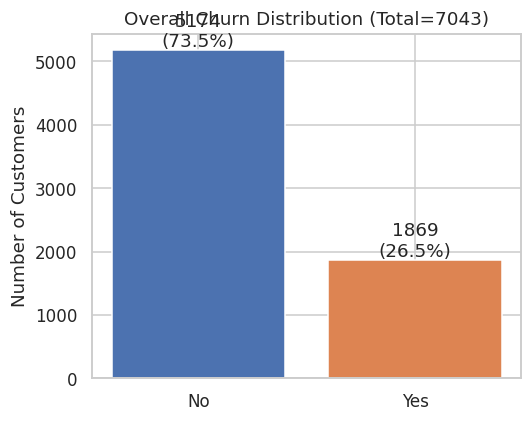

In [7]:
fig, ax = plt.subplots(figsize=(5,4))
counts = df['Churn'].value_counts()
ax.bar(counts.index, counts.values, color=['#4C72B0','#DD8452'])
for i,v in enumerate(counts.values):
    ax.text(i, v+50, f"{v}\n({v/len(df)*100:.1f}%)", ha='center')
ax.set_title('Overall Churn Distribution (Total=7043)')
ax.set_ylabel('Number of Customers')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/01_overall_churn.png')
plt.show()


**Interpretation:** About 1 in 4 customers (26.5%) has churned — a substantial base rate that justifies a closer look at *which* segments drive it.

## 4. Churn by Contract Type

In [8]:
contract_churn = df.groupby('Contract')['ChurnFlag'].agg(['mean','count']).sort_values('mean', ascending=False)
contract_churn['mean'] = (contract_churn['mean']*100).round(1)
contract_churn.rename(columns={'mean':'churn_rate_%','count':'n_customers'})


,churn_rate_%,n_customers
Contract,,
Month-to-month,42.7,3875
One year,11.3,1473
Two year,2.8,1695


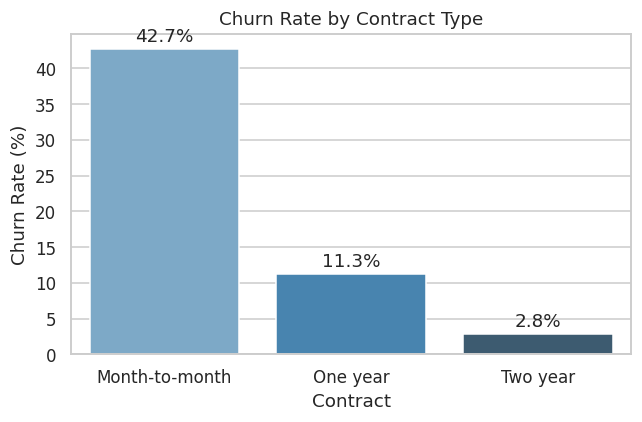

In [9]:
order = ['Month-to-month','One year','Two year']
t = df.groupby('Contract')['ChurnFlag'].mean().reindex(order)*100

fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(x=t.index, y=t.values, hue=t.index, legend=False, palette='Blues_d', ax=ax)
ax.set_title('Churn Rate by Contract Type')
ax.set_xlabel('Contract'); ax.set_ylabel('Churn Rate (%)')
for i,v in enumerate(t.values):
    ax.text(i, v+1, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/02_churn_by_contract.png')
plt.show()


**Interpretation:** Contract type is the single strongest churn driver we found — month-to-month customers churn at **42.7%**, versus **11.3%** for one-year and just **2.8%** for two-year contracts. Locking customers into longer terms is strongly associated with retention.

## 5. Churn by Tenure

In [10]:
tenure_churn = (df.groupby('tenure_group', observed=True)['ChurnFlag'].mean()*100).round(1)
tenure_churn


tenure_group
0-12     47.4
13-24    28.7
25-36    21.6
37-48    19.0
49-60    14.4
61-72     6.6
Name: ChurnFlag, dtype: float64

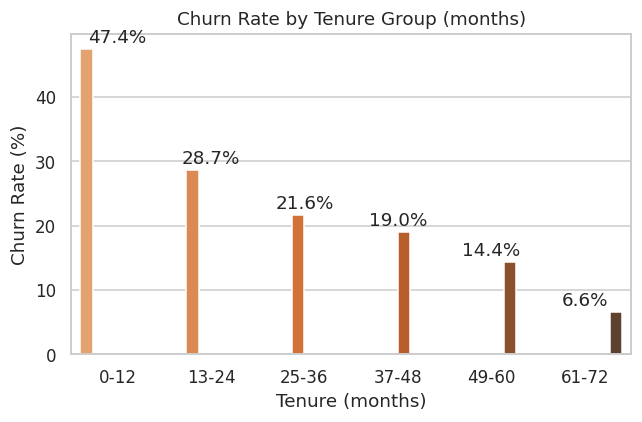

In [11]:
t = df.groupby('tenure_group', observed=True)['ChurnFlag'].mean()*100

fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(x=t.index, y=t.values, hue=t.index, legend=False, palette='Oranges_d', ax=ax)
ax.set_title('Churn Rate by Tenure Group (months)')
ax.set_xlabel('Tenure (months)'); ax.set_ylabel('Churn Rate (%)')
for i,v in enumerate(t.values):
    ax.text(i, v+1, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/03_churn_by_tenure.png')
plt.show()


**Interpretation:** Churn is heavily concentrated in new customers — **47.4%** churn rate in the first year, falling steadily to **6.6%** for customers with 61-72 months of tenure. The average tenure of churned customers is ~18 months (median 10) vs. ~38 months for retained customers. Early-tenure customers need the most retention attention.

## 6. Churn by Monthly Charges

In [12]:
print(df.groupby('Churn')['MonthlyCharges'].agg(['mean','median']).round(2))
print()
print((df.groupby('charges_group', observed=True)['ChurnFlag'].mean()*100).round(1))


        mean  median
Churn               
No     61.27   64.43
Yes    74.44   79.65

charges_group
Low         11.2
Mid-Low     24.6
Mid-High    37.5
High        32.9
Name: ChurnFlag, dtype: float64


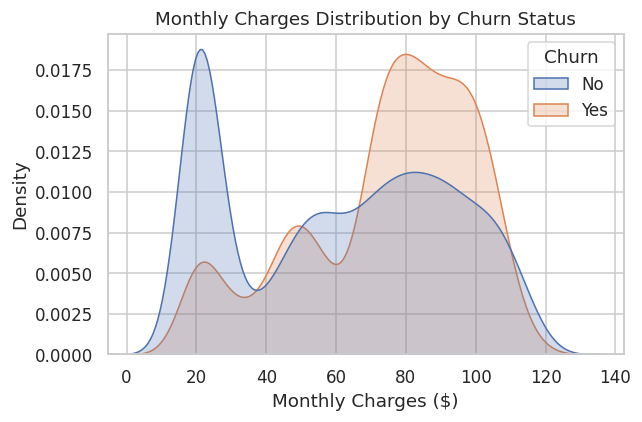

In [13]:
fig, ax = plt.subplots(figsize=(6,4))
sns.kdeplot(data=df, x='MonthlyCharges', hue='Churn', fill=True, common_norm=False, ax=ax)
ax.set_title('Monthly Charges Distribution by Churn Status')
ax.set_xlabel('Monthly Charges ($)')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/04_monthlycharges_by_churn.png')
plt.show()


**Interpretation:** Churned customers pay more on average (**$74.44** vs **$61.27** for retained customers). Churn rate rises from **11.2%** in the lowest charge quartile to **~33-38%** in the mid-high/high quartiles — bill size is correlated with churn risk, likely via the fiber-optic segment below.

## 7. Churn by Internet Service

In [14]:
internet_churn = (df.groupby('InternetService')['ChurnFlag'].mean()*100).round(1)
internet_churn


InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: ChurnFlag, dtype: float64

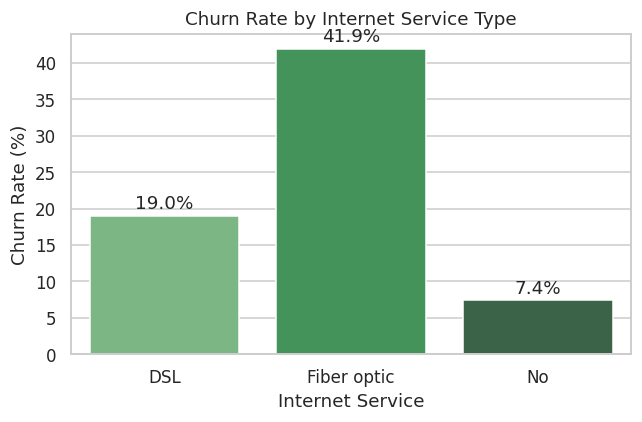

In [15]:
t = df.groupby('InternetService')['ChurnFlag'].mean()*100

fig, ax = plt.subplots(figsize=(6,4))
sns.barplot(x=t.index, y=t.values, hue=t.index, legend=False, palette='Greens_d', ax=ax)
ax.set_title('Churn Rate by Internet Service Type')
ax.set_xlabel('Internet Service'); ax.set_ylabel('Churn Rate (%)')
for i,v in enumerate(t.values):
    ax.text(i, v+1, f"{v:.1f}%", ha='center')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/05_churn_by_internet.png')
plt.show()


**Interpretation:** Fiber optic customers churn at **41.9%**, far above DSL (**19.0%**) and customers with no internet service (**7.4%**). This likely reflects both higher fiber pricing and possibly service/competition issues worth investigating further.

## 8. Churn by Payment Method

In [16]:
payment_churn = (df.groupby('PaymentMethod')['ChurnFlag'].mean()*100).round(1).sort_values(ascending=False)
payment_churn


PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64

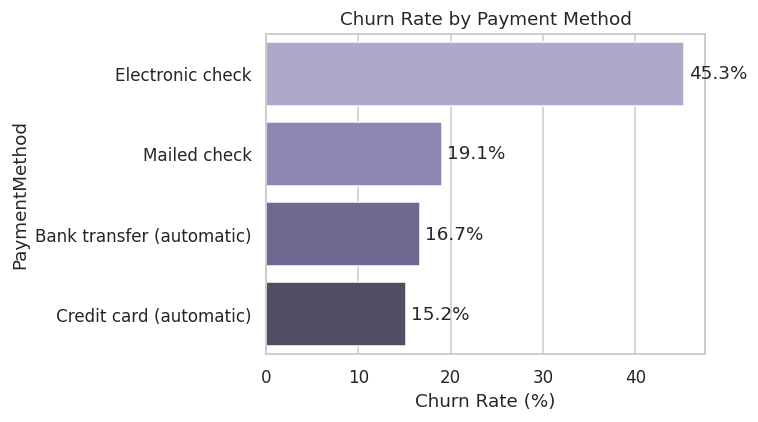

In [17]:
t = payment_churn

fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(x=t.values, y=t.index, hue=t.index, legend=False, palette='Purples_d', ax=ax)
ax.set_title('Churn Rate by Payment Method')
ax.set_xlabel('Churn Rate (%)')
for i,v in enumerate(t.values):
    ax.text(v+0.5, i, f"{v:.1f}%", va='center')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/06_churn_by_payment.png')
plt.show()


**Interpretation:** Electronic check users churn at **45.3%** — dramatically higher than automatic payment methods (bank transfer **16.7%**, credit card **15.2%**) or mailed check (**19.1%**). Customers not on auto-pay are a clear risk segment, possibly linked to lower engagement/commitment.

## 9. Churn by Demographics: Senior Citizen, Partner, Dependents

In [18]:
demo_cols = ['SeniorCitizen','Partner','Dependents']
for c in demo_cols:
    print(df.groupby(c)['ChurnFlag'].agg(['mean','count']).round(3))
    print()


                mean  count
SeniorCitizen              
No             0.236   5901
Yes            0.417   1142

          mean  count
Partner              
No       0.330   3641
Yes      0.197   3402

             mean  count
Dependents              
No          0.313   4933
Yes         0.155   2110



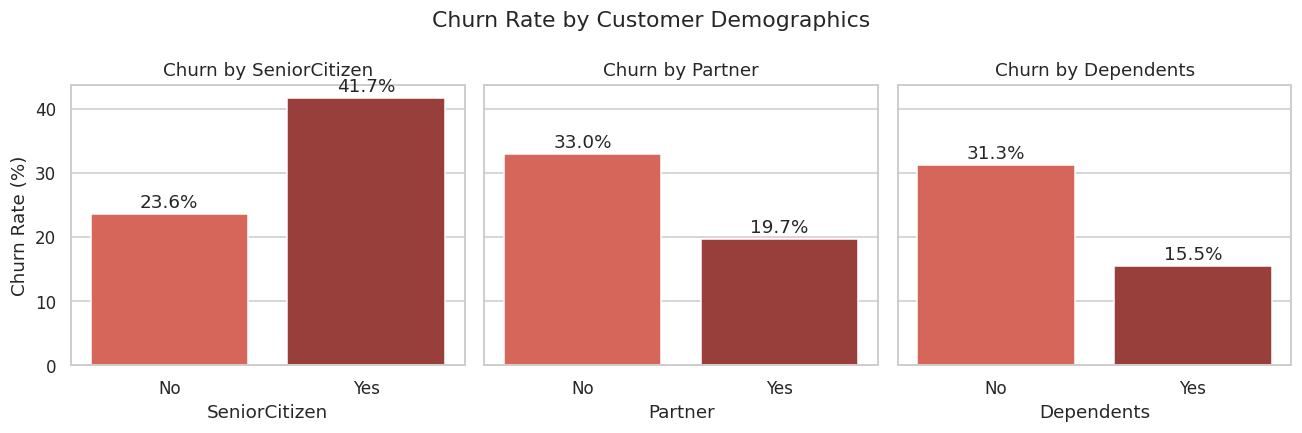

In [19]:
fig, axes = plt.subplots(1,3, figsize=(12,4), sharey=True)
for ax,col in zip(axes, demo_cols):
    t = (df.groupby(col)['ChurnFlag'].mean()*100)
    sns.barplot(x=t.index, y=t.values, hue=t.index, legend=False, palette='Reds_d', ax=ax)
    ax.set_title(f'Churn by {col}')
    ax.set_ylabel('Churn Rate (%)')
    for i,v in enumerate(t.values):
        ax.text(i, v+1, f"{v:.1f}%", ha='center')
plt.suptitle('Churn Rate by Customer Demographics')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/07_churn_by_demographics.png')
plt.show()


**Interpretation:** Senior citizens churn nearly twice as often as non-seniors (**41.7%** vs **23.6%**). Customers without a partner (**33.0%** vs **19.7%**) or without dependents (**31.3%** vs **15.5%**) also churn more -- households with fewer family ties to the service appear less locked in.

## 10. Churn by Selected Add-on Services

In [20]:
service_cols = ['OnlineSecurity','TechSupport','StreamingTV','StreamingMovies']
for c in service_cols:
    print(df.groupby(c)['ChurnFlag'].agg(['mean','count']).round(3))
    print()


                      mean  count
OnlineSecurity                   
No                   0.418   3498
No internet service  0.074   1526
Yes                  0.146   2019

                      mean  count
TechSupport                      
No                   0.416   3473
No internet service  0.074   1526
Yes                  0.152   2044

                      mean  count
StreamingTV                      
No                   0.335   2810
No internet service  0.074   1526
Yes                  0.301   2707

                      mean  count
StreamingMovies                  
No                   0.337   2785
No internet service  0.074   1526
Yes                  0.299   2732



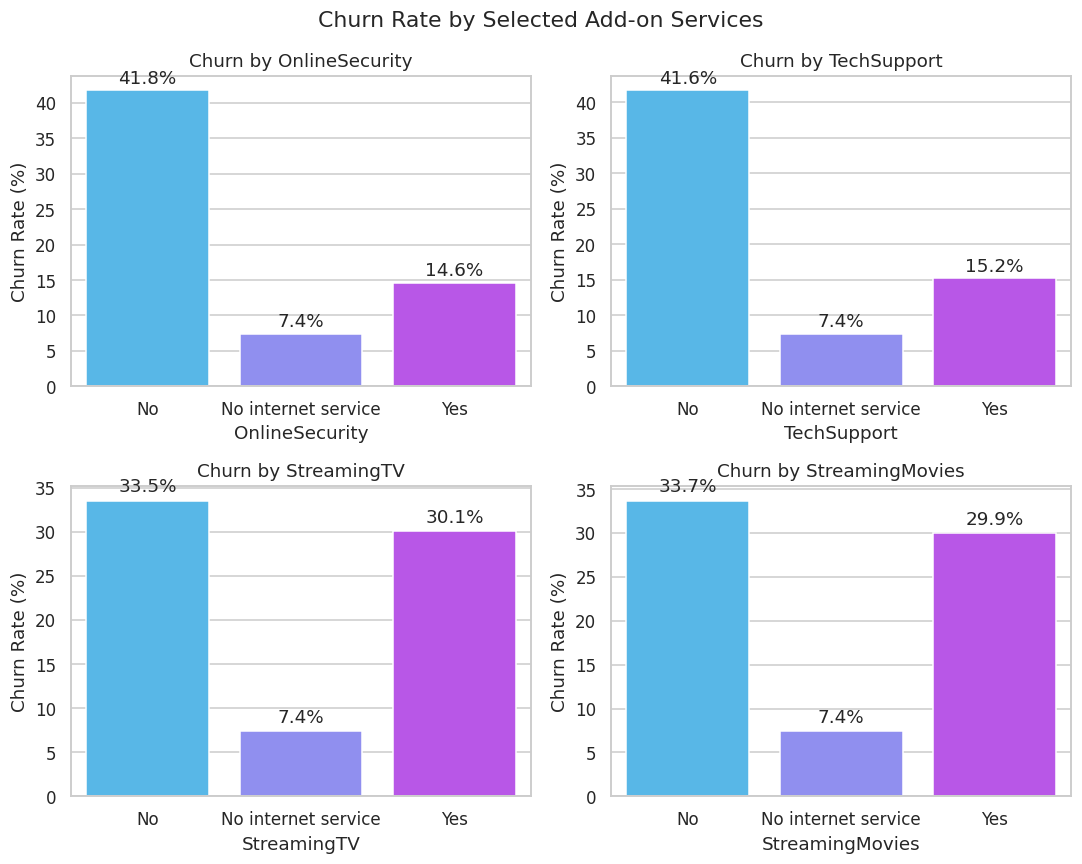

In [21]:
fig, axes = plt.subplots(2,2, figsize=(10,8))
for ax,col in zip(axes.flat, service_cols):
    t = df.groupby(col)['ChurnFlag'].mean()*100
    order = [c for c in ['No','No internet service','Yes'] if c in t.index]
    t = t.reindex(order)
    sns.barplot(x=t.index, y=t.values, hue=t.index, legend=False, palette='cool', ax=ax)
    ax.set_title(f'Churn by {col}')
    ax.set_ylabel('Churn Rate (%)')
    for i,v in enumerate(t.values):
        ax.text(i, v+1, f"{v:.1f}%", ha='center')
plt.suptitle('Churn Rate by Selected Add-on Services')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/08_churn_by_services.png')
plt.show()


**Interpretation:** Customers *without* OnlineSecurity (**41.8%**) or TechSupport (**41.6%**) churn far more than those with these services (~15%). Streaming add-ons (TV/Movies) show a much weaker relationship with churn (~30-34% either way), suggesting security/support services matter more for retention than entertainment add-ons.

## 11. Combined View: Contract x Internet Service

In [22]:
pivot = df.pivot_table(index='Contract', columns='InternetService', values='ChurnFlag', aggfunc='mean')*100
pivot = pivot.round(1)
pivot


InternetService,DSL,Fiber optic,No
Contract,,,
Month-to-month,32.2,54.6,18.9
One year,9.3,19.3,2.5
Two year,1.9,7.2,0.8


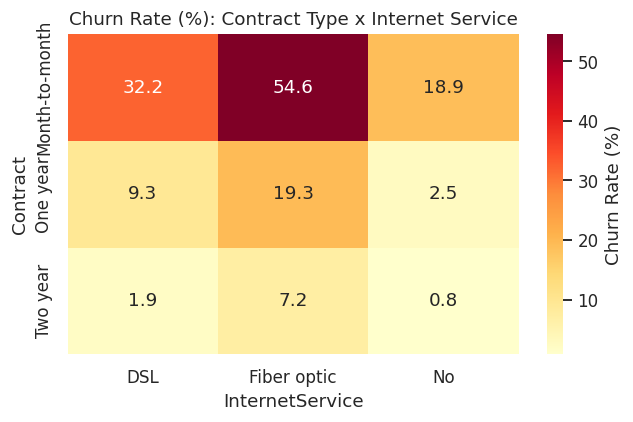

In [23]:
fig, ax = plt.subplots(figsize=(6,4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax, cbar_kws={'label':'Churn Rate (%)'})
ax.set_title('Churn Rate (%): Contract Type x Internet Service')
plt.tight_layout()
plt.savefig(f'{FIG_DIR}/09_heatmap_contract_internet.png')
plt.show()


**Interpretation:** The highest-risk segment is unambiguous — **month-to-month + fiber optic customers churn at 54.6%**, more than half. Two-year contract customers churn below 8% regardless of internet type. Contract length is the dominant lever, with fiber optic amplifying risk within any given contract term.

## 12. Key Findings Summary

1. **Overall churn rate is 26.5%** (1,869 of 7,043 customers) — a meaningful base rate worth active management.
2. **Contract type is the strongest driver of churn.** Month-to-month customers churn at 42.7%, vs. 11.3% for one-year and 2.8% for two-year contracts. Converting month-to-month customers to longer terms is likely the single highest-leverage retention action.
3. **Churn is concentrated in early tenure.** 47.4% of customers with 0-12 months tenure churn, falling to 6.6% by 61-72 months. New customers need the most proactive engagement/onboarding support.
4. **Fiber optic and higher bills correlate with churn.** Fiber optic customers churn at 41.9% (vs 19.0% DSL, 7.4% no internet), and churned customers pay ~$13/month more on average ($74.44 vs $61.27). The worst combination — month-to-month + fiber optic — churns at 54.6%.
5. **Non-automatic payment is a red flag.** Electronic check users churn at 45.3%, roughly 3x the rate of customers on automatic bank transfer (16.7%) or credit card (15.2%) payments.
6. **Lack of support services predicts churn more than lack of entertainment services.** Customers without OnlineSecurity or TechSupport churn at ~42%, vs ~15% for those with these services — a much bigger gap than seen for StreamingTV/Movies (~30-34% either way).
7. **Household ties reduce churn.** Senior citizens churn more (41.7% vs 23.6%), and customers without a partner (33.0% vs 19.7%) or dependents (31.3% vs 15.5%) also churn more — suggesting single/senior customers are a segment worth targeted retention offers.

**Handoff note for Power BI (Member 7):** `telco_with_ids.csv` (same folder as this notebook's outputs) contains the merged, ready-to-model dataset with `customerID`, `ChurnFlag`, `tenure_group`, and `charges_group` fields already derived, matching the groupings used in the charts above.